
Image Classification: CPU vs GPU
=====================

Overview
----------------
1. Memahami struktur dataset ``CIFAR10`` (https://www.cs.toronto.edu/~kriz/cifar.html)
2. Mendesain arsitektur sebuah model CNN
3. Membuat beberapa fungsi pendukung (dataloader, train-val-test, dll)
4. Train-val-test model
5. Komparasi running di CPU dan GPU
6. Melakukan transfer learning



INSPEKSI DATA
=====================


A. Inspeksi data part 1: mengetahui dictionary keywords yang dimiliki dataset
----------------


In [1]:
#sebenarnya dapat dilakukan dengan package torchvision sebagai berikut:
# trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

#
import pickle as pk
def unpickle(file):
    with open(file, 'rb') as fo:
        dict = pk.load(fo, encoding='bytes')
    return dict

root_data = "C:/Users/theos/Desktop/cifar-10-batches-py/"
data_batch = unpickle(root_data+"data_batch_1")
data_key = list(data_batch.keys())
print(data_key)

[b'batch_label', b'labels', b'data', b'filenames']


B. Inspeksi data part 2: mengetahui jumlah sample dan dimensinya
----------------


In [2]:
#
jumlah_sample = len(data_batch[data_key[2]])
print("Jumlah sample yang ada pada file adalah: "+str(jumlah_sample))

sample_ke = 1
sample = data_batch[data_key[2]][sample_ke]
print("Dimensi sample adalah: "+str(sample.shape))
#print(sample.max())

Jumlah sample yang ada pada file adalah: 10000
Dimensi sample adalah: (3072,)


C. Inspeksi data part 3: visualisasi sample
----------------


Shape image adalah: (32, 32, 3)


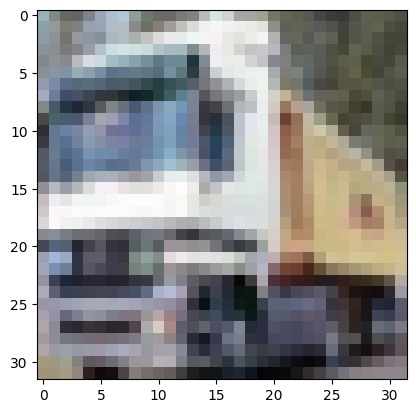

In [3]:
#reshape
import numpy as np
image_red = np.array(sample[0:1024]).reshape((32,32,1)) #tinggi x lebar x channel
image_green = np.array(sample[1024:2048]).reshape((32,32,1))
image_blue = np.array(sample[2048:3072]).reshape((32,32,1))

#gabungkan image rgb
image_rgb = np.concatenate((image_red, image_green, image_blue), axis=2)
print("Shape image adalah: "+str(image_rgb.shape))

#visualisasikan
%matplotlib inline
from matplotlib import pyplot as plt
plt.imshow(image_rgb)
plt.show()


In [4]:
#cek label class-nya
label_cls = data_batch[data_key[1]][sample_ke]
print("classnya adalah: "+str(label_cls))

def one_hot(lbl):
    one_hot_arr = np.zeros(10)
    one_hot_arr[lbl] = 1
    return one_hot_arr

#cek konversi one_hot encodingnya
print(one_hot(label_cls))

classnya adalah: 9
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


MENDESAIN ARSITEKTUR CNN
=====================

### Arsitektur: 3xconv_block --> 3xfc_block

### conv_block = conv_layer+relu+maxpool

### fc_block = fc_layer+relu atau sigmoid

A. TRAIN FROM SCRATCH
----------------


In [5]:
import torch.nn as nn


class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3)
        self.fc1 = nn.Linear(64, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.flatten = nn.Flatten()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.globalpool = nn.AdaptiveAvgPool2d(1)
        self.relu = nn.ReLU()
        self.sigm = nn.Sigmoid()

    def forward(self, x):
        x = x / 255 #normalisasi dari 0 - 255 ke 0 - 1
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.flatten(self.globalpool(x))
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.sigm(self.fc3(x))
        return x

print(ConvNet())

ConvNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (globalpool): AdaptiveAvgPool2d(output_size=1)
  (relu): ReLU()
  (sigm): Sigmoid()
)


B. TRANSFER LEARNING
----------------


In [6]:
import torchvision.models as models
import torchvision.transforms as transforms

class EffNet_clf(nn.Module):
    def __init__(self):
        super().__init__()
        n_fmap_b0 = [[32,16], [24], [40], [80,112], [192,320,1280]]
        n_fmap_b1 = [[32,16], [24], [40], [80,112], [192,320,1280]]
        n_fmap_b2 = [[32,16], [24], [48], [88,120], [208,352,1408]]
        n_fmap_b3 = [[40,24], [32], [48], [96,136], [232,384,1536]] 
        n_fmap_b4 = [[48,24], [32], [56], [112,160], [272,448,1792]]
        n_fmap_b7 = [[64,32], [48], [80], [160,224], [384,640,2560]]
        
        self.rgb_normalizer = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        self.RGB_encoder = models.efficientnet_b0(pretrained=True) #PRETRAINED DARI IMAGENET
        self.RGB_encoder.classifier[1] = nn.Linear(n_fmap_b0[4][-1], 10)
        self.flatten = nn.Flatten()
        self.sigm = nn.Sigmoid()

    def forward(self, rgb):
        rgb = self.rgb_normalizer(rgb)
        RGB_features0 = self.RGB_encoder.features[0](rgb)
        RGB_features1 = self.RGB_encoder.features[1](RGB_features0)
        RGB_features2 = self.RGB_encoder.features[2](RGB_features1)
        RGB_features3 = self.RGB_encoder.features[3](RGB_features2)
        RGB_features4 = self.RGB_encoder.features[4](RGB_features3)
        RGB_features5 = self.RGB_encoder.features[5](RGB_features4)
        RGB_features6 = self.RGB_encoder.features[6](RGB_features5)
        RGB_features7 = self.RGB_encoder.features[7](RGB_features6)
        RGB_features8 = self.RGB_encoder.features[8](RGB_features7)
        #------------------------------------------------------------------------------------------------
        output = self.sigm(self.RGB_encoder.classifier(self.flatten(self.RGB_encoder.avgpool(RGB_features8))))

        return output

print(EffNet_clf())

C:\Users\theos\AppData\Roaming\Python\Python312\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\theos\AppData\Roaming\Python\Python312\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


EffNet_clf(
  (rgb_normalizer): Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  (RGB_encoder): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 

MEMBUAT FUNGSI-FUNGSI PENDUKUNG
=====================


A. DATALOADER
----------------


In [7]:
from torch.utils.data import Dataset

class myData(Dataset):
    def __init__(self, root_data, batch_files):
        
        #buat empty list untuk menyimpan semuanya
        self.dataset_label = []
        self.dataset_data = []
        
        #loop pada semua batch
        for batch_file in batch_files:
            #baca data
            data_batch = unpickle(root_data+batch_file)
            data_key = list(data_batch.keys())
            #gabungkan
            self.dataset_label.append(data_batch[data_key[1]])
            self.dataset_data.append(data_batch[data_key[2]]) 
        
        #concat semua menjadi 1 kesatuan
        self.dataset_label = np.concatenate(self.dataset_label, axis=0)
        self.dataset_data = np.concatenate(self.dataset_data, axis=0)

    def __len__(self):
        return len(self.dataset_label)
    
    def __getitem__(self, index):
        data = dict()
        #label class
        data['label'] = one_hot(self.dataset_label[index])
        #image data
        img_red = np.array(self.dataset_data[index][0:1024]).reshape((32,32,1))
        img_green = np.array(self.dataset_data[index][0:1024]).reshape((32,32,1))
        img_blue = np.array(self.dataset_data[index][0:1024]).reshape((32,32,1))
        img_rgb = np.concatenate((img_red, img_green, img_blue), axis=2) 
        data['image'] = img_rgb.transpose(2,0,1) #pindah dari HxWxC menjadi CxHxW
        
        return data
    

B. TRAINING-VALIDATION
----------------


In [8]:
!pip install tqdm
import torch.nn.functional as F
from tqdm.notebook import tqdm
#pip install --upgrade ipywidgets

#Class untuk penyimpanan dan perhitungan update loss
class AverageMeter(object):
    def __init__(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    #update kalkulasi
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count
        

#FUNGSI TRAINING
def train(data_loader, model, writer, cur_epoch, device, optimizer):
    #buat variabel untuk menyimpan kalkulasi loss
    loss = AverageMeter()

    #masuk ke mode training, pytorch
    model = model.to(device, dtype=torch.float)
    model.train()

    #visualisasi progress training dengan tqdm
    prog_bar = tqdm()
    prog_bar.reset(total=len(data_loader))

    #training....
    total_batch = len(data_loader)
    batch_ke = 0
    for data in data_loader:
        cur_step = cur_epoch*total_batch + batch_ke

        gt_label = data['label'].to(device, dtype=torch.float)
        image_rgb = data['image'].to(device, dtype=torch.float)

        #forward pass
        pred_label = model(image_rgb)

        #kalkulasi loss
        bce_loss = F.binary_cross_entropy(pred_label, gt_label, reduction='mean')

        #backpro, kalkulasi gradient, dan update bobot2 pada network model
        optimizer.zero_grad()
        bce_loss.backward() 
        optimizer.step()

        #hitung rata-rata (avg) loss, dan metric untuk batch-batch yang telah diproses
        loss.update(bce_loss.item())

        #update visualisasi progress bar
        postfix = OrderedDict([('train_loss', loss.avg)])

        #tambahkan ke summary writer
        writer.add_scalar('train_loss', bce_loss.item(), cur_step)

        prog_bar.set_postfix(postfix)
        prog_bar.update()
        batch_ke += 1
    prog_bar.refresh()

    return postfix


#FUNGSI VALIDATION
def validate(data_loader, model, writer, cur_epoch, device):
    #buat variabel untuk menyimpan kalkulasi loss
    loss = AverageMeter()

    #masuk ke mode eval torch
    model = model.to(device, dtype=torch.float)
    model.eval()
    
    with torch.no_grad():
        #visualisasi progress training dengan tqdm
        prog_bar = tqdm()
        prog_bar.reset(total=len(data_loader))

        #training....
        total_batch = len(data_loader)
        batch_ke = 0
        for data in data_loader:
            cur_step = cur_epoch*total_batch + batch_ke

            gt_label = data['label'].to(device, dtype=torch.float)
            image_rgb = data['image'].to(device, dtype=torch.float)

            #forward pass
            pred_label = model(image_rgb)

            #kalkulasi loss
            bce_loss = F.binary_cross_entropy(pred_label, gt_label, reduction='mean')

            #backpro, kalkulasi gradient, dan update bobot2 pada network model
            #optimizer.zero_grad()
            #bce_loss.backward() 
            #optimizer.step()

            #hitung rata-rata (avg) loss, dan metric untuk batch-batch yang telah diproses
            loss.update(bce_loss.item())

            #update visualisasi progress bar
            postfix = OrderedDict([('val_loss', loss.avg)])

            #tambahkan ke summary writer
            writer.add_scalar('val_loss', bce_loss.item(), cur_step)

            prog_bar.set_postfix(postfix)
            prog_bar.update()
            batch_ke += 1
        prog_bar.refresh()

    return postfix



Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


TRAIN-VAL-TEST MODEL
=====================


A. KONFIGURASI TRAINING-VALIDATION
----------------

In [10]:
from torch import torch
from collections import OrderedDict
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import DataLoader
import pandas as pd
import os

#IMPORT MODEL UNTUK DITRAIN
model = ConvNet() #ConvNet EffNet_clf

#KONFIGURASI OPTIMIZER
optima = optim.SGD(model.parameters(), lr=0.0025, momentum=0.9)

#BUAT DATA BATCH: NxCxHxW
root_data = "C:/Users/theos/Desktop/cifar-10-batches-py/"
train_set = myData(root_data, ['data_batch_1', 'data_batch_3', 'data_batch_5'])
val_set = myData(root_data, ['data_batch_2', 'data_batch_4'])
print("Jumlah sample training: "+str(len(train_set)))
print("Jumlah sample validation: "+str(len(val_set)))
dataloader_train = DataLoader(train_set, batch_size=10, shuffle=True, num_workers=4) 
dataloader_val = DataLoader(val_set, batch_size=10, shuffle=False, num_workers=4)

#buat dictionary log untuk menyimpan training log di CSV dan tensorboard
save_dir = os.getcwd() +"/EffNet_clf/"
os.makedirs(save_dir, exist_ok=True)
log = OrderedDict([
    ('epoch', []),
    ('val_loss', []),
    ('train_loss', []), 
    ('elapsed_time', [])])
writer = SummaryWriter(save_dir)

Jumlah sample training: 30000
Jumlah sample validation: 20000


B. MULAI TRAINING-VALIDATION
----------------

In [ ]:
import time

#SET Device yang akan dipakai
device = torch.device("cpu") #cuda cpu
print(device)

for epoch in range(1): #ulang sebanyak n epoch
    print("Epoch: {:05d}------------------------------------------------".format(epoch))
    
    start_time = time.time() #waktu mulai
    train_log = train(dataloader_train, model, writer, epoch, device, optima)
    val_log = validate(dataloader_val, model, writer, epoch, device)
    torch.save(model.state_dict(), save_dir+'model.pth')
    elapsed_time = time.time() - start_time #hitung elapsedtime
    
    print(train_log)
    print(val_log)
    print(elapsed_time)
    
    log['epoch'].append(epoch)
    log['val_loss'].append(val_log['val_loss'])
    log['train_loss'].append(train_log['train_loss'])
    log['elapsed_time'].append(elapsed_time)
    pd.DataFrame(log).to_csv(save_dir+'trainval_log.csv', index=False)
    
    epoch += 1

torch.cuda.empty_cache()

cpu
Epoch: 00000------------------------------------------------


0it [00:00, ?it/s]

C. TEST MODEL
----------------

[b'batch_label', b'labels', b'data', b'filenames']
Jumlah sample yang ada pada file adalah: 10000
Dimensi sample adalah: (3072,)
Shape image adalah: (32, 32, 3)


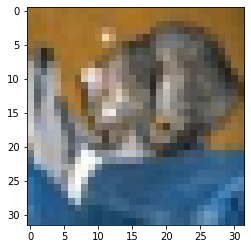

classnya adalah: 3
[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


In [14]:
root_data = "C:/Users/theos/Desktop/cifar-10-batches-py/"
data_batch = unpickle(root_data+"test_batch")
data_key = list(data_batch.keys())
print(data_key)

jumlah_sample = len(data_batch[data_key[2]])
print("Jumlah sample yang ada pada file adalah: "+str(jumlah_sample))

sample_ke = 0
sample = data_batch[data_key[2]][sample_ke]
print("Dimensi sample adalah: "+str(sample.shape))

#reshape
image_red = np.array(sample[0:1024]).reshape((32,32,1)) #tinggi x lebar x channel
image_green = np.array(sample[1024:2048]).reshape((32,32,1))
image_blue = np.array(sample[2048:3072]).reshape((32,32,1))

#gabungkan image rgb
image_rgb = np.concatenate((image_red, image_green, image_blue), axis=2)
print("Shape image adalah: "+str(image_rgb.shape))

#visualisasikan
plt.imshow(image_rgb)
plt.show()

#cek label class-nya
label_cls = data_batch[data_key[1]][sample_ke]
print("classnya adalah: "+str(label_cls))

#cek konversi one_hot encodingnya
print(one_hot(label_cls))

In [15]:
#cek prediksi model
input_img = np.expand_dims(image_rgb.transpose(2,0,1), axis=0)
tensor_input = torch.from_numpy(input_img).to(device, dtype=torch.float)
pred_lbl = model(tensor_input)
print(pred_lbl)
pred_cls = torch.argmax(pred_lbl)
print(pred_cls)

tensor([[0.0523, 0.0090, 0.0282, 0.0281, 0.0725, 0.0041, 0.5484, 0.0080, 0.0283,
         0.0142]], device='cuda:0', grad_fn=<SigmoidBackward0>)
tensor(6, device='cuda:0')


D. TEST KE SELURUH SAMPLE
----------------

In [16]:
#

#FUNGSI TEST
def test(data_loader, model, device):
    #buat variabel untuk menyimpan kalkulasi loss
    metric = AverageMeter()
    
    #buat dictionary log untuk menyimpan training log di CSV
    logx = OrderedDict([
        ('batch', []),
        ('test_acc', []),
        ('elapsed_time', [])])

    #masuk ke mode eval torch
    model.eval()
    
    with torch.no_grad():
        #visualisasi progress training dengan tqdm
        prog_bar = tqdm()
        prog_bar.reset(total=len(data_loader))

        #training....
        total_batch = len(data_loader)
        batch_ke = 0
        for data in data_loader:
            gt_label = data['label'].to(device, dtype=torch.float)
            image_rgb = data['image'].to(device, dtype=torch.float)

            #forward pass
            start_time = time.time() #waktu mulai
            pred_label = model(image_rgb)
            elapsed_time = time.time() - start_time #hitung elapsedtime

            #kalkulasi metric
            pred_cls = torch.argmax(pred_label)
            gt_cls = torch.argmax(gt_label)
            acc = torch.eq(pred_cls, gt_cls).long()

            #hitung rata-rata (avg) loss, dan metric untuk batch-batch yang telah diproses
            metric.update(acc.item())

            #update visualisasi progress bar
            postfix = OrderedDict([('acc', metric.avg)])
            
            #simpan ke log
            logx['batch'].append(batch_ke)
            logx['test_acc'].append(acc.item())
            logx['elapsed_time'].append(elapsed_time)
            pd.DataFrame(logx).to_csv(save_dir+'test_log.csv', index=False)
            
            batch_ke += 1  
            prog_bar.set_postfix(postfix)
            prog_bar.update()
        prog_bar.refresh()
        
        #ketika semua sudah selesai, hitung rata2 performa pada log
        logx['batch'].append("avg")
        logx['test_acc'].append(np.mean(logx['test_acc']))
        logx['elapsed_time'].append(np.mean(logx['elapsed_time']))
        pd.DataFrame(logx).to_csv(save_dir+'test_log.csv', index=False)

    return postfix


#BUAT DATA BATCH: NxCxHxW
test_set = myData(root_data, ['test_batch'])
print("Jumlah sample test: "+str(len(test_set)))
dataloader_test = DataLoader(test_set, batch_size=1, shuffle=False, num_workers=4)

start_time = time.time() #waktu mulai
test_log = test(dataloader_test, model, device)
elapsed_time = time.time() - start_time #hitung elapsedtime
print(test_log)
print(elapsed_time)
torch.cuda.empty_cache()

Jumlah sample test: 10000


0it [00:00, ?it/s]

OrderedDict([('acc', 0.4272)])
397.73918890953064
